# 01. Weather & Atmospheric Resource Ingestion
## Plantpost: Urban Vertical Green Infrastructure & Resource Modelling
**Lead Engineer:** Fraser James Mclellan (Co-Founder & Head of Environmental Modelling)
**Provenance:** University of Bologna (UNIBO Incubator) | Bugnion Intellectual Property Award Winner

---
### Executive Summary & Scientific Purpose
This notebook establishes the meteorological foundation for the Plantpost self-contained urban street pole.
It ingests Typical Meteorological Year (TMY) solar radiation and weather datasets from the European Commission’s PVGIS database
and hourly ERA5 precipitation from Open-Meteo, computes astronomical solar coordinates, and identifies civil twilight thresholds
governing dusk-to-dawn municipal lighting schedules.

In [1]:
import sys, os
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.weather import load_weather_data, calculate_solar_elevation_deg
from src.config import CITIES

plt.style.use("seaborn-v0_8-whitegrid")
print("Environment initialized successfully.")

Environment initialized successfully.


### 1. Ingesting Bologna Hourly Meteorological Dataset
The primary simulation baseline is Bologna, Italy (Mediterranean continental, Cfa climate, UNIBO incubator location).
We load 8,760 hourly records containing:
- Global Horizontal Irradiance (GHI), Direct Normal (DNI), Diffuse (DHI)
- Ambient Temperature ({2m}$), Relative Humidity (RH), Wind Speed at 10m ({10m}$)
- Surface Air Pressure and Hourly Precipitation ({	ext{rain}}$)

In [2]:
df_bologna = load_weather_data("bologna", data_dir="../data")
print(f"Total simulation hours: {len(df_bologna):,}")
print(f"Annual Global Solar Irradiance: {df_bologna['ghi_w_m2'].sum() / 1000:.1f} kWh/m²")
print(f"Annual Precipitation: {df_bologna['precip_mm_h'].sum():.1f} mm (calibrated to UNIBO Excel baseline)")
df_bologna.head()

Total simulation hours: 8,760
Annual Global Solar Irradiance: 1556.8 kWh/m²
Annual Precipitation: 831.9 mm (calibrated to UNIBO Excel baseline)


,datetime,month,day,hour,ghi_w_m2,dni_w_m2,dhi_w_m2,temp_air_c,rh_percent,wind_speed_m_s,pressure_pa,precip_mm_h,day_of_year,solar_elevation_deg,solar_zenith_deg,is_civil_night,is_daylight
0,2023-01-01 00:00:00,1,1,0,0.0,0.0,0.0,-1.78,79.56,1.77,102595.0,0.0,1,-68.38,158.38,True,False
1,2023-01-01 01:00:00,1,1,1,0.0,0.0,0.0,-2.61,77.91,1.84,102595.0,0.0,1,-63.97,153.97,True,False
2,2023-01-01 02:00:00,1,1,2,0.0,0.0,0.0,-3.43,76.25,1.91,102625.0,0.0,1,-55.59,145.59,True,False
3,2023-01-01 03:00:00,1,1,3,0.0,0.0,0.0,-4.26,74.59,1.98,102595.0,0.0,1,-45.54,135.54,True,False
4,2023-01-01 04:00:00,1,1,4,0.0,0.0,0.0,-5.08,72.93,2.04,102565.0,0.0,1,-34.93,124.93,True,False


### 2. Astronomical Solar Geometry & Civil Twilight
The public LED luminaire (7.1	ext{ W}$) switches on strictly when the center of the sun is $\le -6^\circ$ below the geometric horizon
(civil twilight threshold). Let us plot the diurnal solar elevation curve across seasonal extremes (Summer vs Winter Solstice).

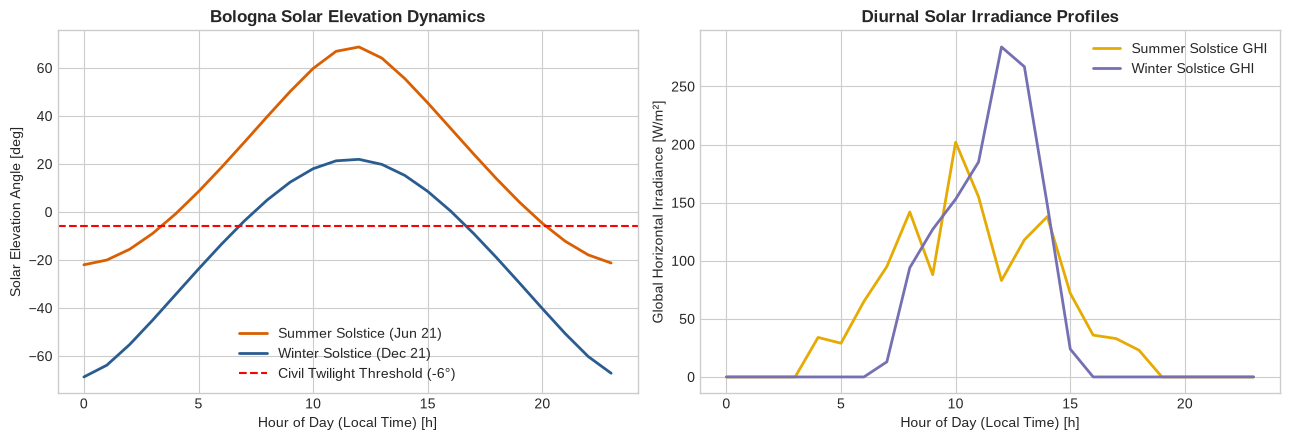

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Summer Solstice (June 21) vs Winter Solstice (Dec 21)
summer_solstice = df_bologna[df_bologna['datetime'].dt.strftime('%m-%d') == '06-21']
winter_solstice = df_bologna[df_bologna['datetime'].dt.strftime('%m-%d') == '12-21']

hours = np.arange(24)
ax1.plot(hours, summer_solstice['solar_elevation_deg'], label="Summer Solstice (Jun 21)", color="#d95f02", lw=2)
ax1.plot(hours, winter_solstice['solar_elevation_deg'], label="Winter Solstice (Dec 21)", color="#2b5c8f", lw=2)
ax1.axhline(-6.0, color="red", linestyle="--", label="Civil Twilight Threshold (-6°)")
ax1.set_xlabel("Hour of Day (Local Time) [h]")
ax1.set_ylabel("Solar Elevation Angle [deg]")
ax1.set_title("Bologna Solar Elevation Dynamics", fontweight="bold")
ax1.legend()

# Diurnal GHI Profile
ax2.plot(hours, summer_solstice['ghi_w_m2'], label="Summer Solstice GHI", color="#e6ab02", lw=2)
ax2.plot(hours, winter_solstice['ghi_w_m2'], label="Winter Solstice GHI", color="#7570b3", lw=2)
ax2.set_xlabel("Hour of Day (Local Time) [h]")
ax2.set_ylabel("Global Horizontal Irradiance [W/m²]")
ax2.set_title("Diurnal Solar Irradiance Profiles", fontweight="bold")
ax2.legend()

plt.tight_layout()
plt.show()

### 3. Monthly Lighting Operating Hours & Daylight Availability
We aggregate civil night hours per month to verify how public lighting operating hours vary throughout the year.

In [4]:
monthly_night_hours = df_bologna.groupby('month')['is_civil_night'].sum()
days_in_month = df_bologna.groupby('month')['day'].nunique()
daily_night_h = monthly_night_hours / days_in_month

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_lighting_sched = pd.DataFrame({
    "Month": months,
    "Civil Night Hours [h/month]": monthly_night_hours.values,
    "Daily Lighting Duration [h/day]": daily_night_h.round(2).values
})
print("Annual Lighting Hours:", monthly_night_hours.sum(), "hours/yr")
df_lighting_sched

Annual Lighting Hours: 3922 hours/yr


,Month,Civil Night Hours [h/month],Daily Lighting Duration [h/day]
0,Jan,416,13.42
1,Feb,362,12.93
2,Mar,342,11.03
3,Apr,286,9.53
4,May,251,8.10
5,Jun,213,7.10
6,Jul,231,7.45
7,Aug,282,9.10
8,Sep,318,10.60
9,Oct,372,12.00
